In [1]:
import sys, os
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

# Data acquisition, cleaning, and EDA

In [2]:
from src.data_loader import prepare_returns
prices, returns = prepare_returns()
returns.head()

,DBS,OCBC,UOB
Date,,,
2014-01-03,-0.007042,-0.015842,-0.015195
2014-01-06,0.002353,-0.015083,-0.002395
2014-01-07,0.001174,-0.012232,-0.006254
2014-01-08,0.019181,0.001025,0.018173
2014-01-09,-0.001729,-0.002051,0.002367


The cleaned panel contains aligned common trading dates and preserves documented extreme observations; the cleaning log records rather than deletes market shocks.

In [3]:
from src.eda_and_intervals import step4
summary = step4()
display(summary)

,Bank,N,Mean,Standard Deviation,Annualised Volatility,Skewness,Excess Kurtosis,Minimum,Q01,10% Quantile,Maximum
0,DBS,2762,0.000556,0.011471,0.182099,0.133886,5.267616,-0.083854,-0.028646,-0.012531,0.075841
1,OCBC,2762,0.000361,0.010215,0.162164,-0.237947,5.031124,-0.069973,-0.026291,-0.010867,0.067468
2,UOB,2762,0.000370,0.010895,0.172958,-0.086233,5.251339,-0.076139,-0.029189,-0.011793,0.069313


Annualised volatility and excess kurtosis quantify substantial dispersion and tail heaviness; the values provide the empirical benchmark for the later intervals and distribution tests.

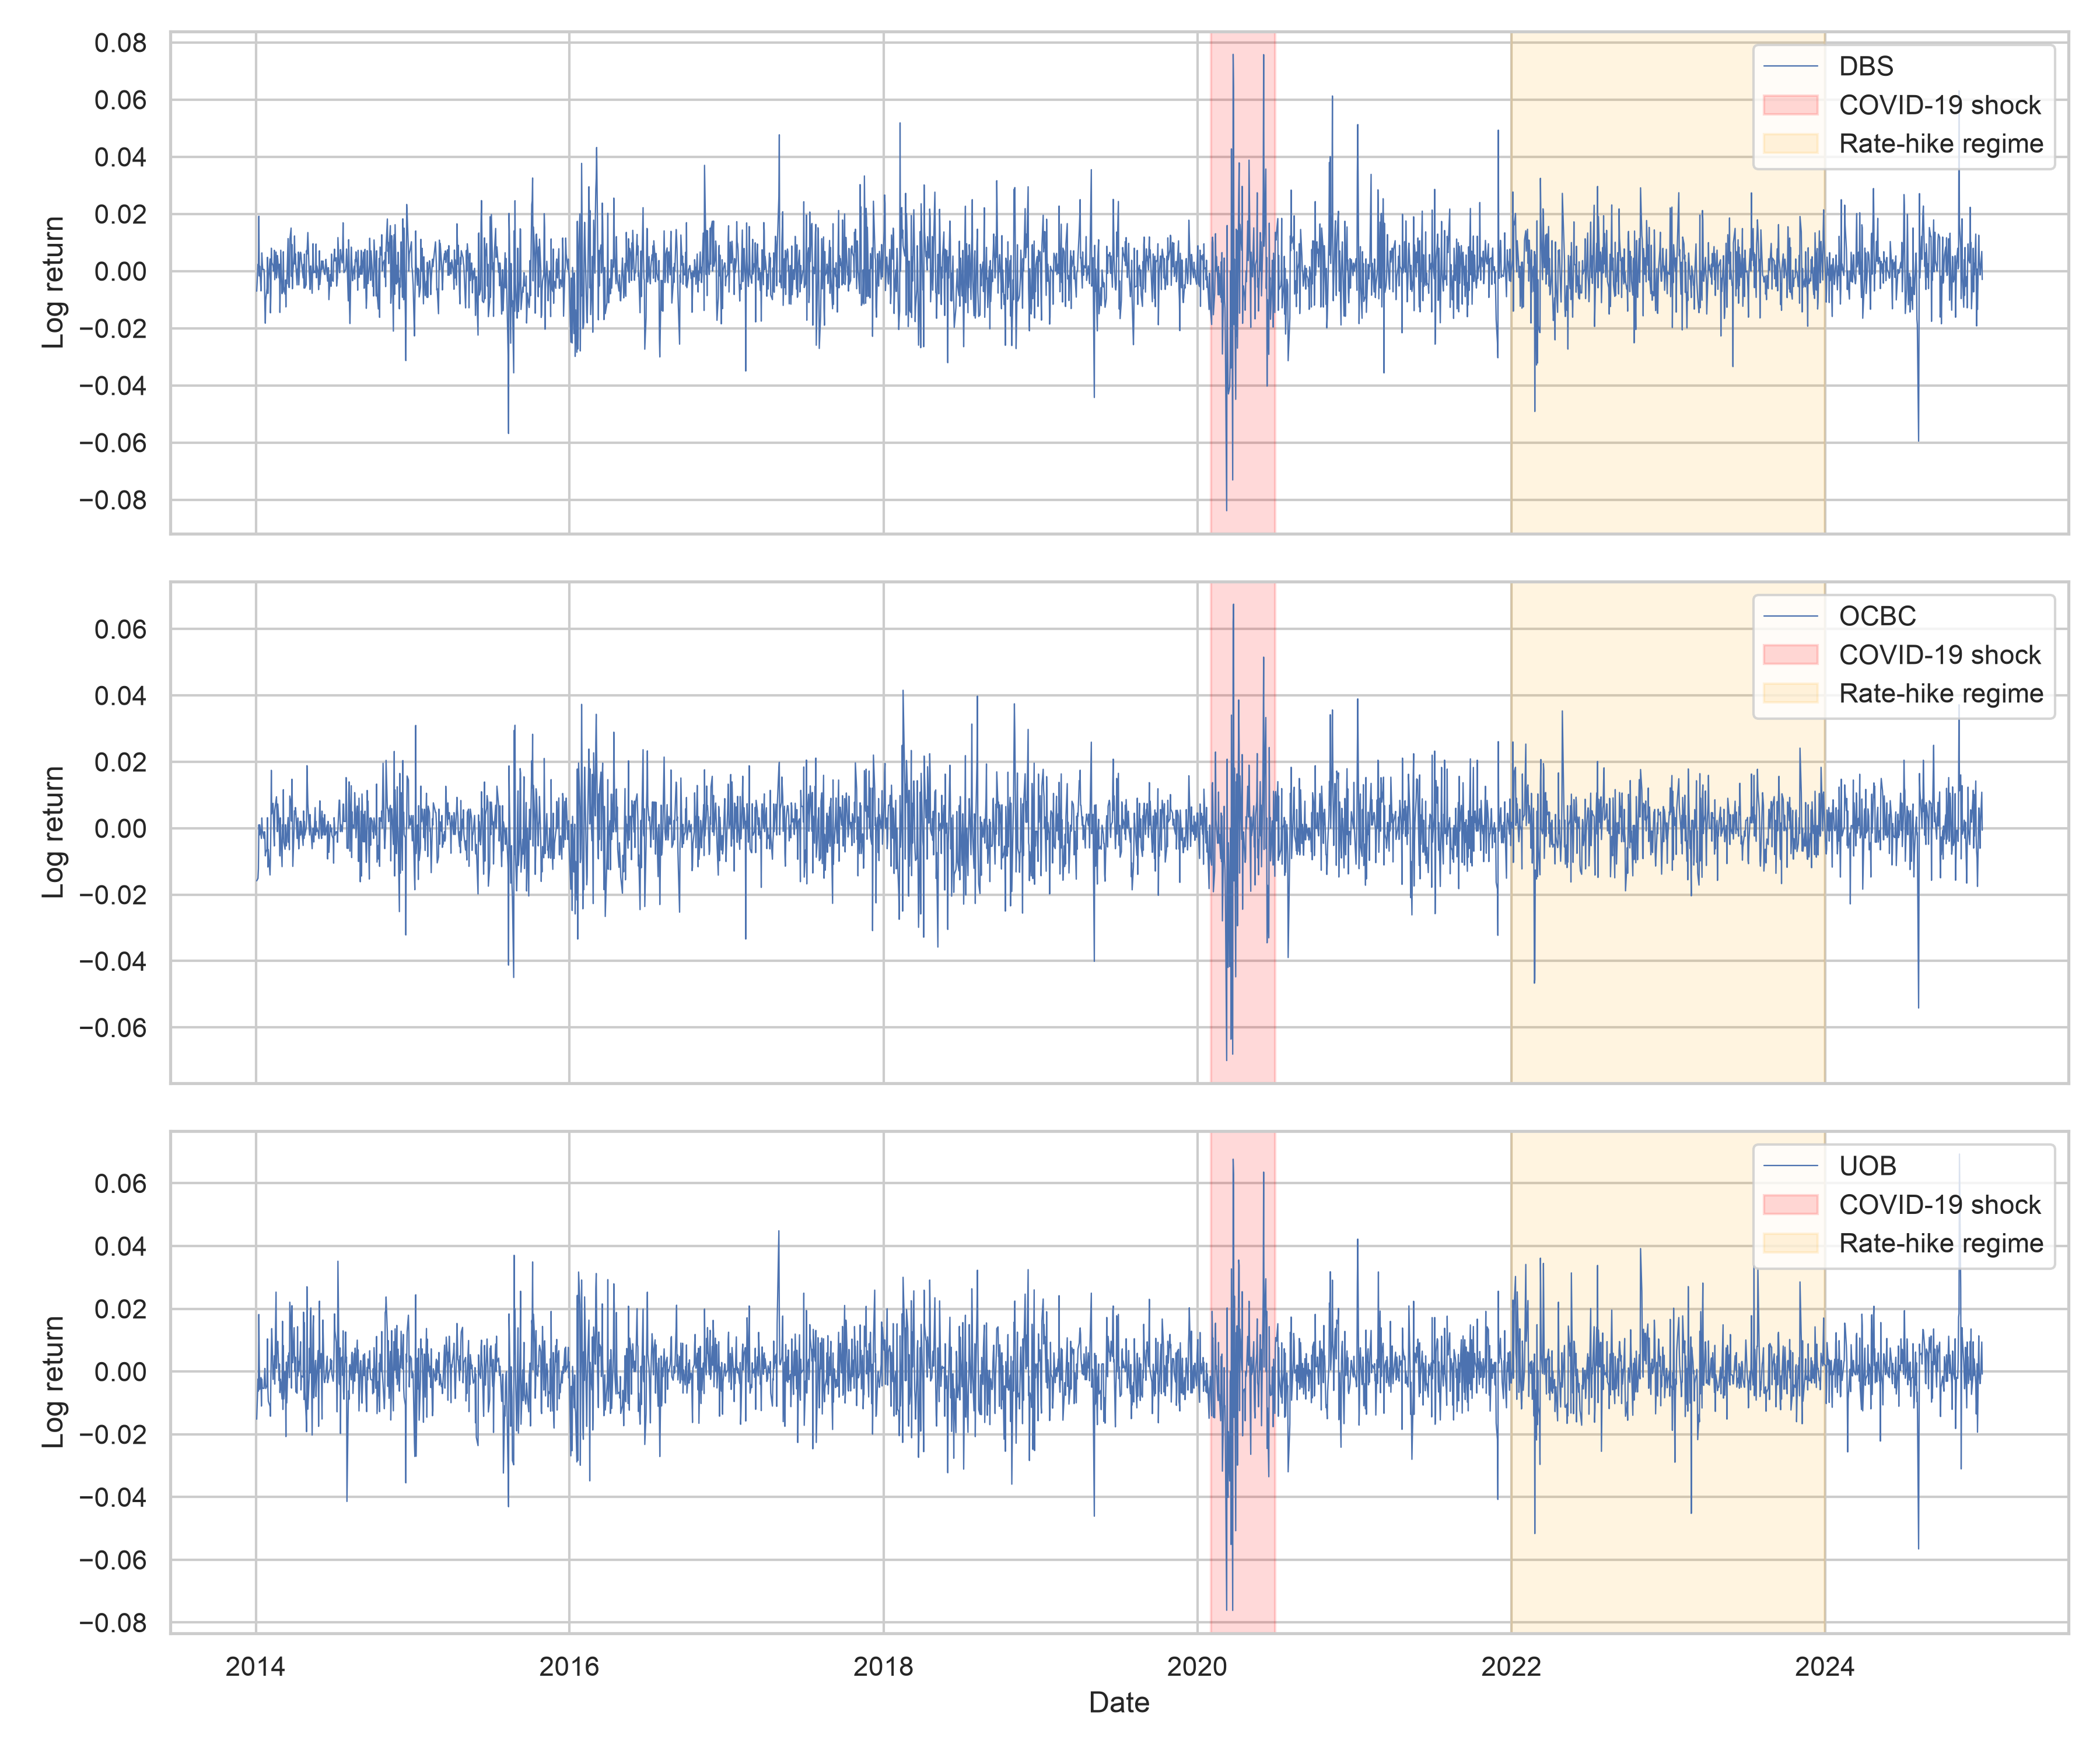

In [4]:
from IPython.display import Image, display
display(Image(filename="outputs/figures/step4_return_series_regimes.png"))

Regime shading makes clear that COVID and later market stress periods produce clusters of unusually large moves rather than independent occasional shocks.

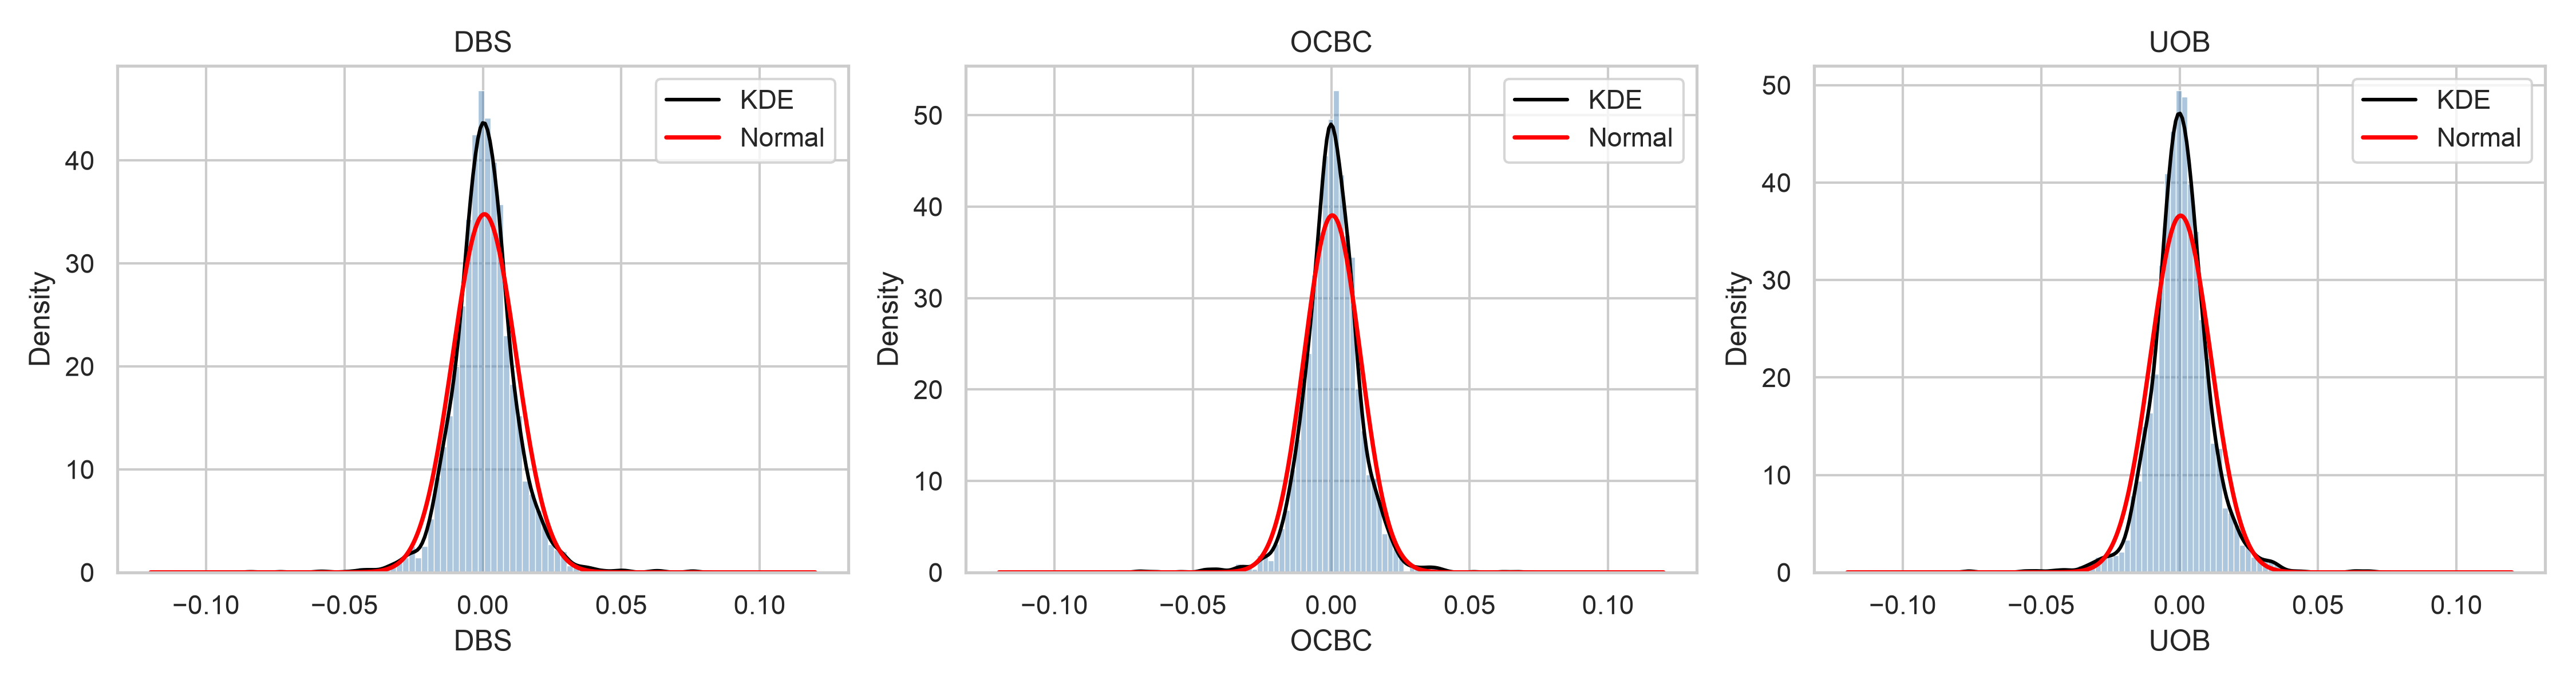

In [5]:
display(Image(filename="outputs/figures/step4_hist_kde_normal.png"))

The histograms/KDEs show sharper centres and heavier shoulders than the fitted Normal, motivating formal distribution comparison.

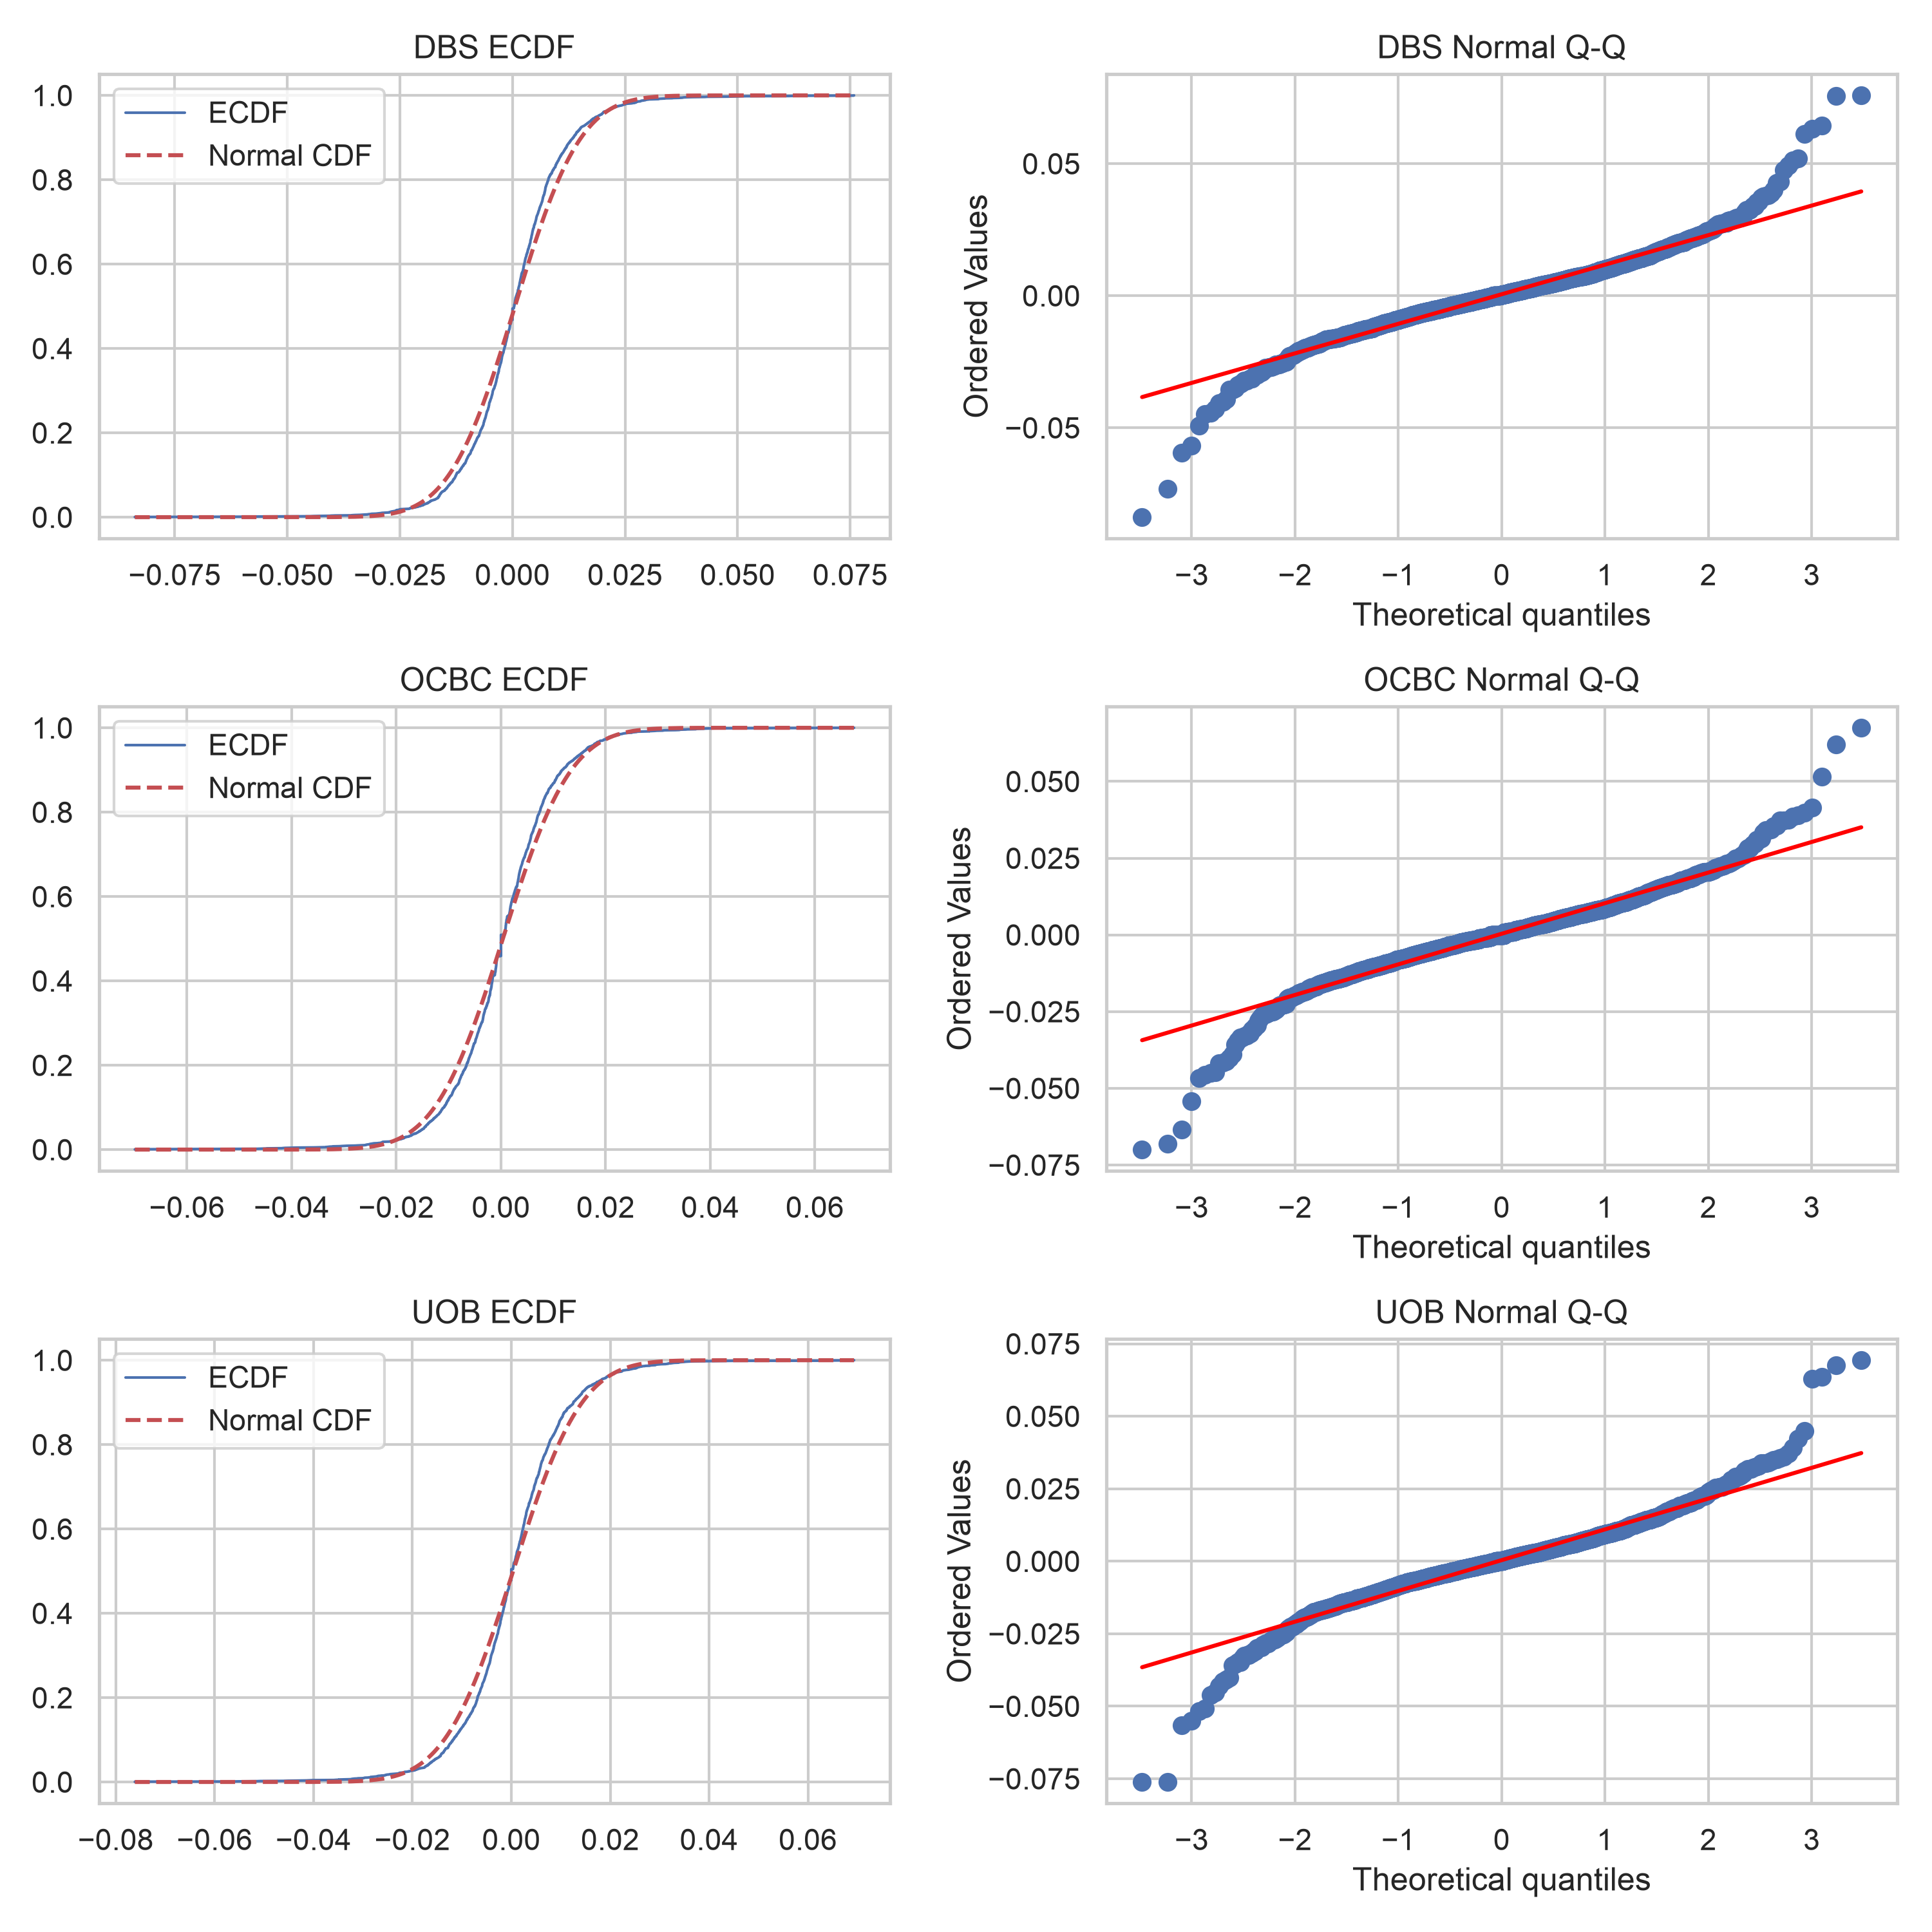

In [6]:
display(Image(filename="outputs/figures/step4_ecdf_and_qq.png"))

ECDF and Normal Q-Q departures at the extreme realisations demonstrate why far-tail Normal risk measures are unreliable.